# Easy Case Study: Amazon Review Sentiment Analysis

**Goal:** Classify product reviews as negative, neutral, or positive. Fine-tune BERT with Hugging Face and compare it with a simple LSTM baseline.

**Designed for Google Colab.** This version avoids TensorFlow and avoids a heavy `datasets` dependency. It uses PyTorch, Transformers, scikit-learn, and pandas, which are commonly available in Colab.

**Dataset:** Upload a CSV named `amazon_reviews.csv` with two columns:
- `review`: review text
- `label`: `negative`, `neutral`, or `positive`

You can create this CSV from Amazon reviews with star ratings using: 1–2 stars = negative, 3 stars = neutral, and 4–5 stars = positive. This is a proxy labeling rule, not perfect ground truth.

**Important:** This notebook is kept simple, but BERT model weights still need to download the first time. Select a GPU in Colab if one is available.


## 1. Install only what is needed

If Colab already has these packages, this should finish quickly without installing TensorFlow or Hugging Face Datasets.

In [1]:
%pip -q install transformers scikit-learn

## 2. Imports and setup

In [2]:
import os, time, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


## 3. Load your review CSV

Upload `amazon_reviews.csv` using the folder icon in Colab. It must contain `review` and `label` columns.

If you do not already have a dataset, you can make a small sample CSV yourself for testing the notebook. For your final case study, state clearly where the reviews came from.

In [5]:
# In Google Colab, uncomment these two lines to upload a CSV:
from google.colab import files
files.upload()

df = pd.read_csv("amazon_reviews_demo(1).csv")
df = df[["review", "label"]].dropna().copy()
df["review"] = df["review"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.lower().str.strip()
df = df[(df["review"] != "") & df["label"].isin(["negative", "neutral", "positive"])]
df = df.drop_duplicates(subset=["review", "label"]).reset_index(drop=True)

label_names = ["negative", "neutral", "positive"]
label_to_id = {name: i for i, name in enumerate(label_names)}
df["label_id"] = df["label"].map(label_to_id).astype(int)

# Keep a manageable sample; change to 2000 or 5000 if your dataset is large.
if len(df) > 3000:
    df = df.groupby("label", group_keys=False).apply(
        lambda g: g.sample(min(len(g), 1000), random_state=SEED)
    ).reset_index(drop=True)

print("Rows:", len(df))
print(df["label"].value_counts())
display(df.head())

Saving amazon_reviews_demo(1).csv to amazon_reviews_demo(1) (1).csv
Rows: 75
label
positive    30
neutral     30
negative    15
Name: count, dtype: int64


,review,label,label_id
0,This phone is fantastic and the battery lasts ...,positive,2
1,Customer review: This phone is fantastic and t...,positive,2
2,Excellent quality for the price. Very happy wi...,positive,2
3,My experience: Excellent quality for the price...,positive,2
4,The headphones sound clear and feel comfortable.,positive,2


## 4. Split data into train, validation, and test sets

In [6]:
train_df, temp_df = train_test_split(
    df, test_size=0.20, random_state=SEED, stratify=df["label_id"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label_id"]
)
print("Train:", len(train_df), "| Validation:", len(val_df), "| Test:", len(test_df))

Train: 60 | Validation: 7 | Test: 8


## 5. Fine-tune BERT

This uses the Hugging Face `Trainer` API. BERT is already pre-trained; training adapts it to the three sentiment labels.

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

...

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


BERT training minutes: 0.26


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1
No log,1.085270,1,0.375000,0.277778


BERT test metrics: {'eval_loss': 1.0852696895599365, 'eval_accuracy': 0.375, 'eval_macro_f1': 0.27777777777777773}
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00         2
     neutral       0.33      0.33      0.33         3
    positive       0.40      0.67      0.50         3

    accuracy                           0.38         8
   macro avg       0.24      0.33      0.28         8
weighted avg       0.28      0.38      0.31         8



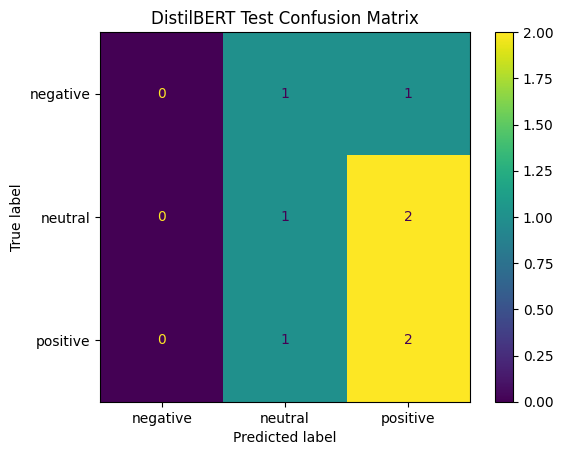

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./sentiment_bert_model/tokenizer_config.json',
 './sentiment_bert_model/tokenizer.json')

In [7]:
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding
)
from torch.utils.data import Dataset as TorchDataset

MODEL_NAME = "distilbert/distilbert-base-uncased"  # smaller/faster than BERT-base
MAX_LENGTH = 128

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class ReviewDataset(TorchDataset):
    def __init__(self, frame):
        self.texts = frame["review"].tolist()
        self.labels = frame["label_id"].tolist()
    def __len__(self):
        return len(self.texts)
    def __getitem__(self, idx):
        item = tokenizer(
            self.texts[idx], truncation=True, max_length=MAX_LENGTH
        )
        item["labels"] = int(self.labels[idx])
        return item

train_ds = ReviewDataset(train_df)
val_ds = ReviewDataset(val_df)
test_ds = ReviewDataset(test_df)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label={i: name for i, name in enumerate(label_names)},
    label2id={name: i for i, name in enumerate(label_names)}
).to(DEVICE)

def metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro")
    }

args = TrainingArguments(
    output_dir="./bert_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=1,  # use 2–3 epochs if time permits
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="eval_macro_f1",
    report_to="none",
    seed=SEED,
    fp16=torch.cuda.is_available()
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=metrics
)

start = time.time()
trainer.train()
bert_train_time = time.time() - start
bert_result = trainer.predict(test_ds)
bert_pred = np.argmax(bert_result.predictions, axis=1)
y_test = test_df["label_id"].to_numpy()

print("BERT training minutes:", round(bert_train_time / 60, 2))
print("BERT test metrics:", trainer.evaluate(test_ds))
print(classification_report(y_test, bert_pred, labels=[0,1,2], target_names=label_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, bert_pred, labels=[0,1,2], display_labels=label_names)
plt.title("DistilBERT Test Confusion Matrix")
plt.show()

trainer.save_model("./sentiment_bert_model")
tokenizer.save_pretrained("./sentiment_bert_model")

## 6. Simple LSTM baseline (PyTorch only)

This avoids TensorFlow entirely. It uses a basic word vocabulary and an LSTM with an embedding layer.

Epoch 1: train loss=1.123, train acc=0.200, val acc=0.143
Epoch 2: train loss=1.116, train acc=0.200, val acc=0.143
Epoch 3: train loss=1.114, train acc=0.200, val acc=0.143
LSTM training minutes: 0.01
              precision    recall  f1-score   support

    negative       0.25      1.00      0.40         2
     neutral       0.00      0.00      0.00         3
    positive       0.00      0.00      0.00         3

    accuracy                           0.25         8
   macro avg       0.08      0.33      0.13         8
weighted avg       0.06      0.25      0.10         8



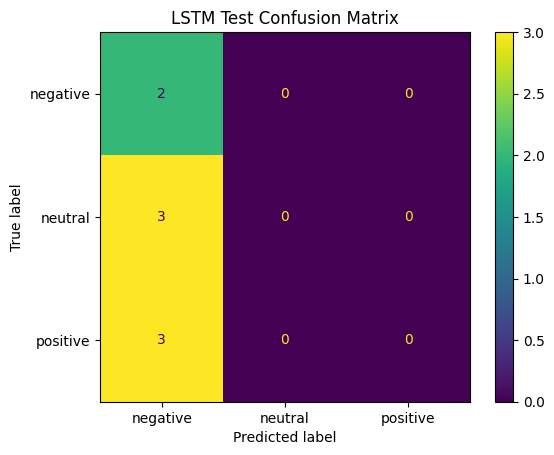

In [8]:
from collections import Counter
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

MAX_VOCAB = 12000
MAX_LEN = 128
PAD, UNK = 0, 1

counter = Counter()
for text in train_df["review"]:
    counter.update(text.lower().split())

vocab = {"<PAD>": PAD, "<UNK>": UNK}
for word, _ in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

def encode_text(text):
    ids = [vocab.get(w, UNK) for w in text.lower().split()[:MAX_LEN]]
    return ids + [PAD] * (MAX_LEN - len(ids))

def make_tensors(frame):
    X = torch.tensor([encode_text(t) for t in frame["review"]], dtype=torch.long)
    y = torch.tensor(frame["label_id"].to_numpy(), dtype=torch.long)
    return TensorDataset(X, y)

train_loader = DataLoader(make_tensors(train_df), batch_size=64, shuffle=True)
val_loader = DataLoader(make_tensors(val_df), batch_size=128)
test_loader = DataLoader(make_tensors(test_df), batch_size=128)

class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, num_classes=3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim, num_classes)
    def forward(self, x):
        x = self.embedding(x)
        _, (h, _) = self.lstm(x)
        return self.fc(self.dropout(h[-1]))

lstm = LSTMClassifier(len(vocab)).to(DEVICE)
optimizer = torch.optim.Adam(lstm.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

def run_epoch(loader, train=False):
    lstm.train(train)
    total_loss, total, correct = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for X, y in loader:
            X, y = X.to(DEVICE), y.to(DEVICE)
            logits = lstm(X)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            total += len(y)
    return total_loss / max(total, 1), correct / max(total, 1)

start = time.time()
for epoch in range(3):
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = run_epoch(val_loader, train=False)
    print(f"Epoch {epoch+1}: train loss={train_loss:.3f}, train acc={train_acc:.3f}, val acc={val_acc:.3f}")
lstm_train_time = time.time() - start

lstm.eval()
lstm_preds = []
with torch.no_grad():
    for X, y in test_loader:
        logits = lstm(X.to(DEVICE))
        lstm_preds.extend(logits.argmax(1).cpu().numpy())

lstm_preds = np.array(lstm_preds)
print("LSTM training minutes:", round(lstm_train_time / 60, 2))
print(classification_report(y_test, lstm_preds, labels=[0,1,2], target_names=label_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, lstm_preds, labels=[0,1,2], display_labels=label_names)
plt.title("LSTM Test Confusion Matrix")
plt.show()

## 7. Final comparison

In [9]:
comparison = pd.DataFrame([
    {
        "Model": "DistilBERT (fine-tuned)",
        "Accuracy": accuracy_score(y_test, bert_pred),
        "Macro-F1": f1_score(y_test, bert_pred, average="macro"),
        "Training time (minutes)": bert_train_time / 60
    },
    {
        "Model": "PyTorch LSTM",
        "Accuracy": accuracy_score(y_test, lstm_preds),
        "Macro-F1": f1_score(y_test, lstm_preds, average="macro"),
        "Training time (minutes)": lstm_train_time / 60
    }
])
display(comparison.round(4))

,Model,Accuracy,Macro-F1,Training time (minutes)
0,DistilBERT (fine-tuned),0.375,0.2778,0.2645
1,PyTorch LSTM,0.250,0.1333,0.0078


## 8. Discussion and conclusion

### Transfer learning
- DistilBERT reuses language knowledge learned during pre-training and fine-tunes it for sentiment.
- This can help when labeled data is limited, but model download and fine-tuning still require time and compute.
- The LSTM baseline learns its word embeddings from this dataset, so it may need more labeled examples.

### Deployment constraints
- **Latency and memory:** transformer models can use more memory; consider smaller models, quantization, or batching.
- **Data quality:** star ratings are noisy proxies for sentiment; sarcasm and mixed opinions are difficult.
- **Privacy:** avoid retaining personal data in logs and secure the prediction API.
- **Monitoring:** monitor errors and class balance as review language changes.

### Final conclusion
Use the comparison table and confusion matrices above to report measured results. Do not claim BERT is better unless your run's results support it. For a fair comparison, both models use the same train/validation/test split.

**Submission checklist:** dataset source and labeling rule, actual metrics, confusion matrices, training time, transfer-learning explanation, and deployment limitations.
